In [ ]:
1. Content Distribution
Comparison between Movies and TV Shows
Percentage-based insights
2. Time-Based Analysis
Growth of Netflix content over the years
Comparison of Movies vs TV Shows over time
3. Country-Based Analysis
Top content-producing countries
Country vs content type comparison
4. Genre Analysis
Most common genres on Netflix
Genre distribution across Movies and TV Shows
5. Duration Analysis
Distribution of movie durations
Identification of common runtime patterns
6. Content Freshness
Difference between release year and Netflix addition year
Understanding whether Netflix favors newer or older content
7. Correlation Analysis
Relationship between numerical features using heatmap

In [1]:
# import the Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#read the dataset
df = pd.read_csv("netflix_titles.csv")

In [5]:
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [7]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [13]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

In [25]:
#data cleaning
#fill missing valuese ( safe method)
df['director'] = df['director'].fillna('unknow')
df['cast'] = df['cast'].fillna('unknow')
df['country'] = df ['country'].fillna('unknow')
df['rating'] = df ['rating'].fillna('Not Rated')

#drop rows with very few missing values
df = df.dropna(subset=['date_added', 'duration'])

#convert date column
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')

#Extract the year
df['year_added'] = df['date_added'].dt.year
df.isnull().sum()


show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
year_added      0
dtype: int64

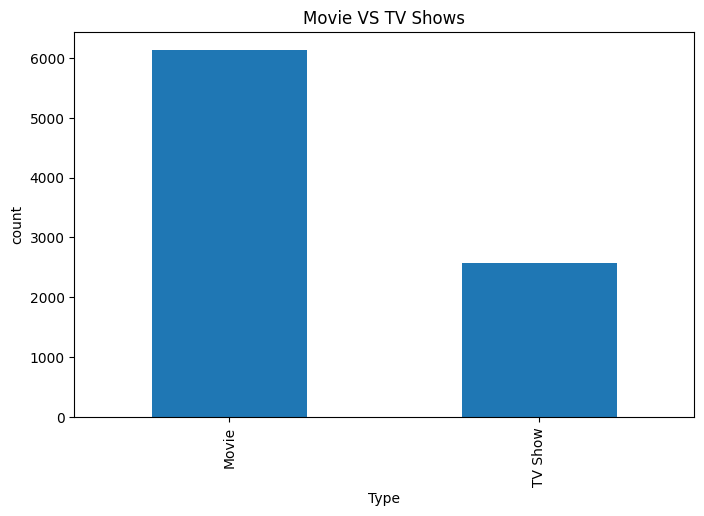

In [27]:
#movies vs tv shows with Percentage-based insights
plt.figure(figsize=(8,5))

df['type'].value_counts().plot(kind='bar')
plt.title("Movie VS TV Shows")
plt.xlabel("Type")
plt.ylabel("count")

plt.show()



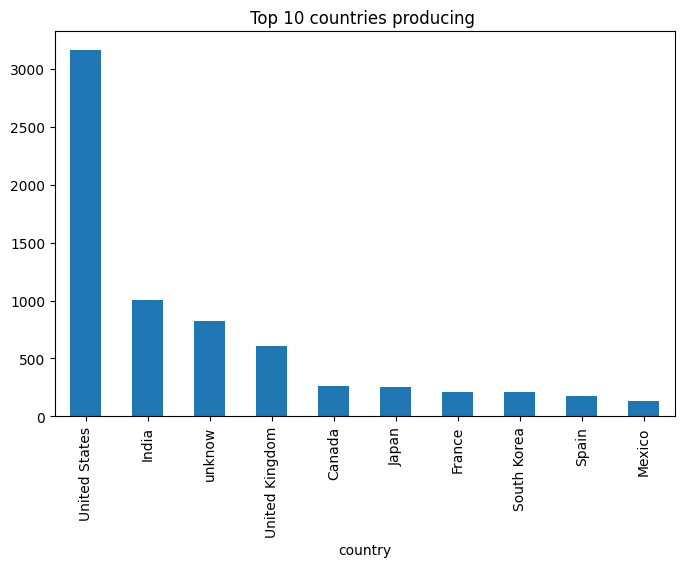

In [33]:
#top 10 countries 
plt.figure(figsize=(8,5))

df['country'] = df['country'].str.split(',').str[0]

df['country'].value_counts().head(10).plot(kind='bar')
plt.title('Top 10 countries producing ')
plt.show()

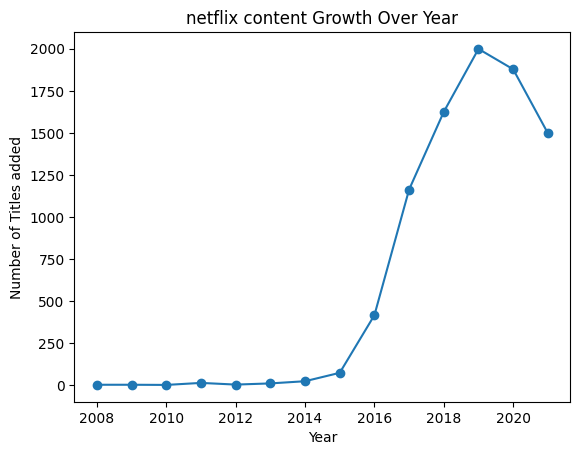

In [35]:
# contend growth trends 
df['year_added'].value_counts().sort_index().plot(kind='line', marker='o')
plt.title("netflix content Growth Over Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles added")
plt.show()

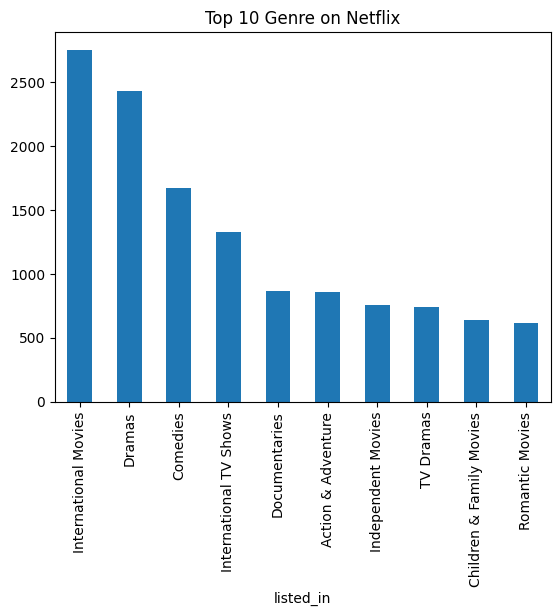

In [41]:
#Top Genre 
genres = df['listed_in'].str.split(',').explode().str.strip()

genres.value_counts().head(10).plot(kind='bar')
plt.title("Top 10 Genre on Netflix")
plt.show()

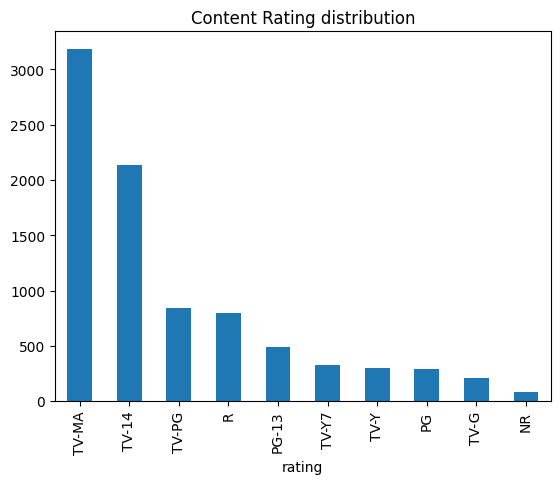

In [45]:
# Ratings analysis
df['rating'].value_counts().head(10).plot(kind='bar')
plt.title("Content Rating distribution")
plt.show()


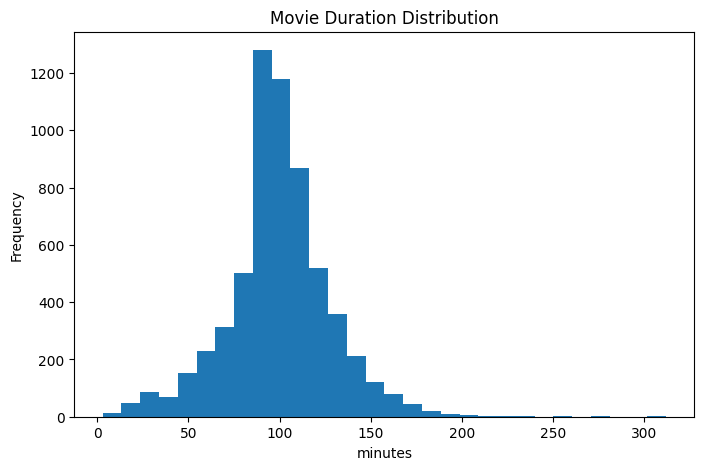

In [47]:
#Duration Analysis
movies = df[df['type'] == 'Movie'].copy()

movies['duration'] = movies['duration'].str.replace('min', '').astype(float)

plt.figure(figsize=(8,5))
movies['duration'].plot(kind='hist', bins=30)

plt.title('Movie Duration Distribution')
plt.xlabel("minutes")

plt.show()


<Figure size 1000x600 with 0 Axes>

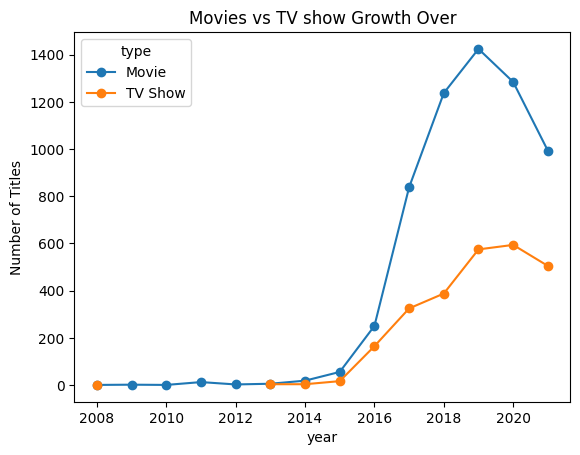

In [59]:
#movie vs Tv shows Growth Over Time 
content_trend = df.groupby(['year_added', 'type']).size().unstack()

plt.figure(figsize=(10,6))
content_trend.plot(kind='line', marker='o')

plt.title('Movies vs TV show Growth Over')
plt.xlabel("year")
plt.ylabel("Number of Titles")
plt.show()


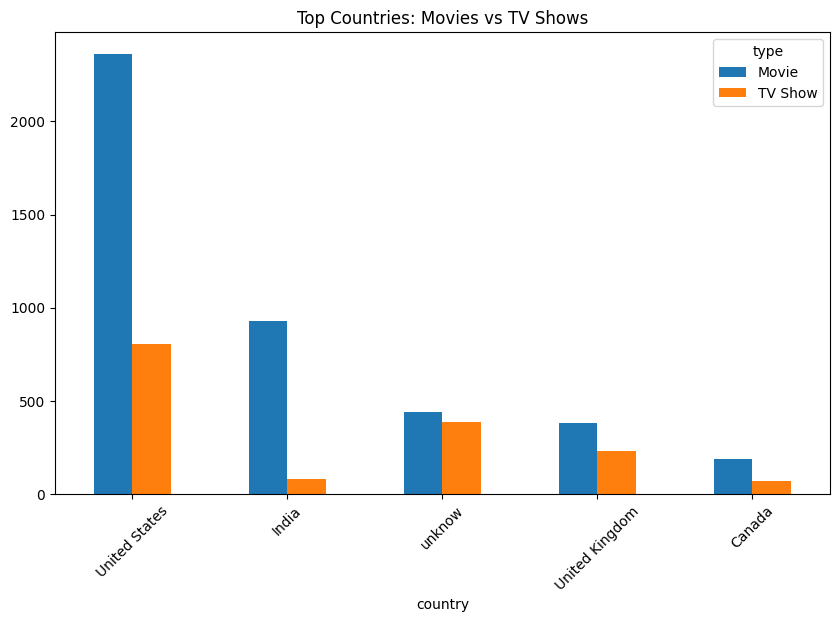

In [63]:
#Country vs Content Type
country_type = df.groupby(['country', 'type']).size().unstack().fillna(0)

top_countries = df['country'].value_counts().head(5).index
country_type.loc[top_countries].plot(kind='bar', figsize=(10,6))

plt.title("Top Countries: Movies vs TV Shows")
plt.xticks(rotation=45)

plt.show()


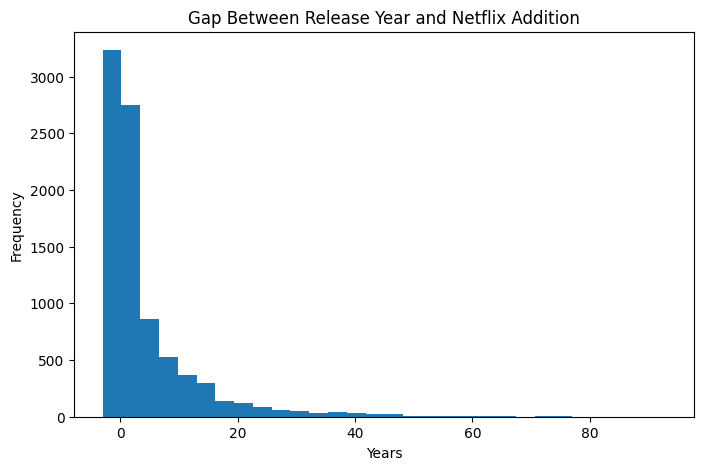

In [65]:
#Release Year vs Added Year 
df['content_age'] = df['year_added'] - df['release_year']

plt.figure(figsize=(8,5))
df['content_age'].plot(kind='hist', bins=30)

plt.title("Gap Between Release Year and Netflix Addition")
plt.xlabel("Years")
plt.show()

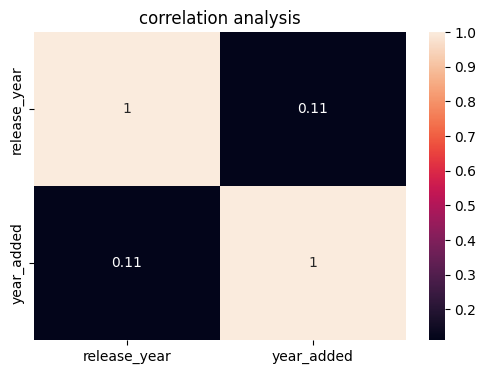

In [71]:
#correclation heatmap
numeric_df= df[['release_year', 'year_added']].dropna()

plt.figure(figsize=(6,4))
sns.heatmap(numeric_df.corr(), annot=True)

plt.title('correlation analysis')
plt.show()